In [1]:
#import libraries 
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 

#loading data 
dataset=load_dataset('lukebarousse/data_jobs') 
df=dataset['train'].to_pandas()  

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])

'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/lukebarousse/data_jobs/resolve/ed776e5a0a8c40ea9d5efbd800772ae52e140f3e/data_jobs.py
Retrying in 1s [Retry 1/5].
Using the latest cached version of the dataset since lukebarousse/data_jobs couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'default' at C:\Users\USER\.cache\huggingface\datasets\lukebarousse___data_jobs\default\0.0.0\ed776e5a0a8c40ea9d5efbd800772ae52e140f3e (last modified on Tue Aug 25 12:49:19 2026).


In [2]:
df.pivot_table(index='job_title_short',aggfunc='size')

job_title_short
Business Analyst              49063
Cloud Engineer                12331
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Machine Learning Engineer     14080
Senior Data Analyst           29216
Senior Data Engineer          44563
Senior Data Scientist         36957
Software Engineer             44929
dtype: int64

In [3]:
df.groupby('job_title_short').size()

job_title_short
Business Analyst              49063
Cloud Engineer                12331
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Machine Learning Engineer     14080
Senior Data Analyst           29216
Senior Data Engineer          44563
Senior Data Scientist         36957
Software Engineer             44929
dtype: int64

In [5]:
df.pivot_table(values='salary_year_avg',index='job_title_short',aggfunc='median')

,salary_year_avg
job_title_short,
Business Analyst,85000.0
Cloud Engineer,90000.0
Data Analyst,90000.0
Data Engineer,125000.0
Data Scientist,127500.0
Machine Learning Engineer,106415.0
Senior Data Analyst,111175.0
Senior Data Engineer,147500.0
Senior Data Scientist,155500.0


In [6]:
df.groupby('job_title_short')['salary_year_avg'].median()

job_title_short
Business Analyst              85000.0
Cloud Engineer                90000.0
Data Analyst                  90000.0
Data Engineer                125000.0
Data Scientist               127500.0
Machine Learning Engineer    106415.0
Senior Data Analyst          111175.0
Senior Data Engineer         147500.0
Senior Data Scientist        155500.0
Software Engineer             99150.0
Name: salary_year_avg, dtype: float64

In [7]:
top_coutries=df['job_country'].value_counts()
top_coutries

job_country
United States               206292
India                        51088
United Kingdom               40375
France                       39922
Germany                      27694
                             ...  
Northern Mariana Islands         4
Lesotho                          3
Mauritania                       3
Bhutan                           3
Maldives                         2
Name: count, Length: 160, dtype: int64

In [8]:
top_coutries=df['job_country'].value_counts().head(6)
top_coutries

job_country
United States     206292
India              51088
United Kingdom     40375
France             39922
Germany            27694
Spain              25100
Name: count, dtype: int64

In [9]:
top_coutries=df['job_country'].value_counts().head(6).index
top_coutries

Index(['United States', 'India', 'United Kingdom', 'France', 'Germany',
       'Spain'],
      dtype='str', name='job_country')

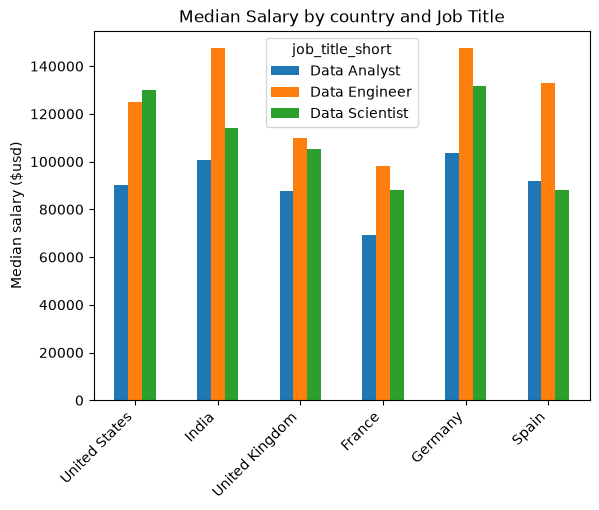

In [19]:
top_coutries=df['job_country'].value_counts().head(6).index 

df_job_country_salary=df.pivot_table(
    values='salary_year_avg',
    index='job_country',
    columns='job_title_short',
    aggfunc='median'

) 

df_job_country_salary=df_job_country_salary.loc[top_coutries] 

job_titles=['Data Analyst','Data Engineer','Data Scientist'] 

df_job_country_salary=df_job_country_salary[job_titles] 

df_job_country_salary.plot(kind='bar')
plt.ylabel('Median salary ($usd)') 
plt.xlabel('')
plt.title('Median Salary by country and Job Title')
plt.xticks(rotation=45, ha='right')
plt.show()

# df_job_country_salary